# SHAPformer on quarter-hourly data: one week of input in days

This notebook follows `training_dataframe.ipynb`, but on the TransnetBW load data in quarter-hourly resolution:

- **input length**: one week (7 · 96 = 672 quarter hours) of past information, including the target,
- **horizon**: one week (672 quarter hours) to forecast,
- **periods**: the past load is explained in seven days of 96 quarter hours each, set with `period_length=96`.

With the 6 covariates, these are 13 feature groups (as with hourly data), so the exact method needs 2<sup>13</sup> = 8192 model evaluations per explanation.

To keep the training time similar to hourly data, only windows that start at full hours are used for training (`window_stride=4`); the validation uses all windows.

Steps:

1. load the data and set up the SHAPformer model,
2. train the model for at most 10 epochs, for testing (or load a trained one),
3. evaluate the forecast errors on the validation year 2019,
4. forecast and explain one week (with the exact method),
5. create dependence plots from 1000 explanations (with the permutation method).

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

from pathlib import Path

import shapformer
from shapformer import SHAPformer

print(f"shapformer {shapformer.__version__} from {shapformer.__file__}")

REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_DIR / "data"  # the datasets (see the README)
MODEL_DIR = REPO_DIR / "models"  # the trained models

TRAINING = False  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = MODEL_DIR / "model_quarter_hourly_one_week.ckpt"

PERIOD_LENGTH = 96  # one day of quarter hours
INPUT_LENGTH = 7 * 96  # one week
HORIZON = 7 * 96  # one week
STEPS_PER_HOUR = 4  # time steps per hour (one time step: 15 minutes)
STEPS_PER_WEEK = 672

## Load the data

The quarter-hourly load of TransnetBW (`transnet_bw.csv`, in MW) is joined with the quarter-hourly weather data (`copernicus_BW.csv`), which is linearly interpolated from hourly reanalysis values. The covariates are the same as in the hourly data, except that the time of day is the quarter of the day (0–95) instead of the hour:

- calendar features: `quarter_of_day`, `day_of_week`, `month` (0–11), `holiday` (taken from the hourly data, by date),
- weather features: `temperature` (converted from K to °C) and `precipitation` (converted from m to mm, small negative values clipped to 0).

The timestamps are local time with their UTC offset, as in the hourly data.

In [2]:
load = pd.read_csv(DATA_DIR / "transnet" / "transnet_bw.csv", parse_dates=[0], index_col=0)
weather = pd.read_csv(DATA_DIR / "transnet" / "copernicus_BW.csv", parse_dates=[0], index_col=0)
df = load.join(weather[["TA-_0002m", "TP-_0000m"]], how="left")
df = df.rename(columns={"TA-_0002m": "temperature", "TP-_0000m": "precipitation"})
df["temperature"] -= 273.15  # K to °C
df["precipitation"] = (df["precipitation"] * 1000).clip(lower=0)  # m to mm

# calendar features from the local timestamps ("YYYY-MM-DD hh:mm:ss+hh:mm")
timestamps = pd.Series(df.index.astype(str), index=df.index)
dates = pd.to_datetime(timestamps.str[:10])
df["quarter_of_day"] = timestamps.str[11:13].astype(int) * 4 + timestamps.str[14:16].astype(int) // 15
df["day_of_week"] = dates.dt.day_of_week
df["month"] = dates.dt.month - 1  # categorical features must start at 0
hourly = pd.read_csv(DATA_DIR / "transnet" / "transnet_bw_hourly.csv", index_col=0)
holidays = hourly.groupby(hourly.index.astype(str).str[:10])["holiday"].max()
df["holiday"] = timestamps.str[:10].map(holidays).astype(int)

df = df[["load", "quarter_of_day", "day_of_week", "month", "holiday", "temperature", "precipitation"]]
print(df)

                              load  quarter_of_day  day_of_week  month  \
cet_cest_timestamp                                                       
2015-01-01 01:00:00+01:00  5370.14               4            3      0   
2015-01-01 01:15:00+01:00  5294.22               5            3      0   
2015-01-01 01:30:00+01:00  5257.57               6            3      0   
2015-01-01 01:45:00+01:00  5197.23               7            3      0   
2015-01-01 02:00:00+01:00  5117.31               8            3      0   
...                            ...             ...          ...    ...   
2019-12-31 22:45:00+01:00  5416.46              91            1     11   
2019-12-31 23:00:00+01:00  5375.34              92            1     11   
2019-12-31 23:15:00+01:00  5325.77              93            1     11   
2019-12-31 23:30:00+01:00  5261.73              94            1     11   
2019-12-31 23:45:00+01:00  5213.03              95            1     11   

                           holiday  t

## Create the model

The same small transformer as in `training_dataframe.ipynb` (one layer, four attention heads, hidden dimension 128). The model gets the input length and `period_length=96`, so the past week is split into seven days. The sequences are four times as long as with hourly data, so the batch size is halved to fit into the GPU memory.

In [3]:
model = SHAPformer(
    target="load",
    feature_categories={
        "quarter_of_day": 96,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "temperature": None,
        "precipitation": None
    },
    d_model=128,
    n_layers=1,
    n_heads=4,
    input_length=INPUT_LENGTH,
    horizon=HORIZON,
    period_length=PERIOD_LENGTH
)
print(f"input length {model.get_input_length()}, horizon {model.get_horizon()}, "
      f"{model.get_n_periods()} periods with the lengths {model.get_period_lengths()}")

input length 672, horizon 672, 7 periods with the lengths (96, 96, 96, 96, 96, 96, 96)


## Train the model (or load a trained model)

As in `training_dataframe.ipynb`, all rows before `VALIDATION_START` are used for training and the rows from there on for validation. For testing, the training runs for at most 20 epochs; the model with the lowest validation loss is restored.

In [4]:
DEVICE = "cuda"
VALIDATION_START = "2019-01-01"
EPOCHS = 20

if TRAINING:
    model.to(DEVICE)
    model = model.fit(df, VALIDATION_START, epochs=EPOCHS, batch_size=64, patience=10, window_stride=4)
    MODEL_DIR.mkdir(exist_ok=True)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 543/543 [02:13<00:00,  4.08it/s]


Epoch 1/20, Training loss: 0.5526145955695193, Validation loss: 0.10505056553268788 (best: 0.10505056553268788), Epochs without improvement: 0/10


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 543/543 [02:14<00:00,  4.03it/s]


Epoch 2/20, Training loss: 0.27715403277900336, Validation loss: 0.07232562931223288 (best: 0.07232562931223288), Epochs without improvement: 0/10


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 543/543 [02:15<00:00,  4.02it/s]


Epoch 3/20, Training loss: 0.2320992281423748, Validation loss: 0.06675401808662787 (best: 0.06675401808662787), Epochs without improvement: 0/10


... (30 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 543/543 [02:24<00:00,  3.75it/s]


Epoch 19/20, Training loss: 0.133961768906639, Validation loss: 0.04988946463198191 (best: 0.03506245886563589), Epochs without improvement: 1/10


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 543/543 [02:21<00:00,  3.83it/s]


Epoch 20/20, Training loss: 0.13249448390461463, Validation loss: 0.03527179437392917 (best: 0.03506245886563589), Epochs without improvement: 2/10
Restored the model from epoch 18 with validation loss 0.03506245886563589.


## Evaluate the forecasts

We forecast from every full hour of the validation year 2019 (each forecast with the full input before it, and all forecasted time steps in the data), and compute the mean absolute error (MAE), the root mean squared error (RMSE) and the mean absolute percentage error (MAPE).

As a reference, the seasonal naive forecast repeats the load of one week earlier.

In [5]:
EVALUATION_STRIDE = 4  # forecast from every EVALUATION_STRIDE-th time step

timestamps = pd.to_datetime(df.index, utc=True)
first_validation_start = int((timestamps < pd.Timestamp(VALIDATION_START, tz="UTC")).sum())
complete = np.concatenate(([0], np.cumsum(df.isna().any(axis=1).to_numpy())))  # number of incomplete rows before
evaluation_starts = [
    s for s in range(first_validation_start, len(df) - HORIZON + 1, EVALUATION_STRIDE)
    if complete[s + HORIZON] == complete[s - max(INPUT_LENGTH, STEPS_PER_WEEK)]
]

load = df["load"].to_numpy()
future_covariates = df.drop(columns="load")
predictions = np.stack([
    model.predict(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON]).to_numpy()
    for s in evaluation_starts
])
actuals = np.stack([load[s:s + HORIZON] for s in evaluation_starts])
naive = np.stack([load[s - STEPS_PER_WEEK:s - STEPS_PER_WEEK + HORIZON] for s in evaluation_starts])
print(f"{len(evaluation_starts)} forecasts of {HORIZON} time steps")


def errors(forecasts):
    error = forecasts - actuals
    return {
        "MAE [MW]": np.abs(error).mean(),
        "RMSE [MW]": np.sqrt((error ** 2).mean()),
        "MAPE [%]": 100 * np.abs(error / actuals).mean()
    }


pd.DataFrame({"SHAPformer": errors(predictions), "seasonal naive (one week earlier)": errors(naive)}).T.round(2)

8592 forecasts of 672 time steps


,MAE [MW],RMSE [MW],MAPE [%]
SHAPformer,225.66,291.48,3.43
seasonal naive (one week earlier),454.86,770.53,6.97


The error per forecasted time step:

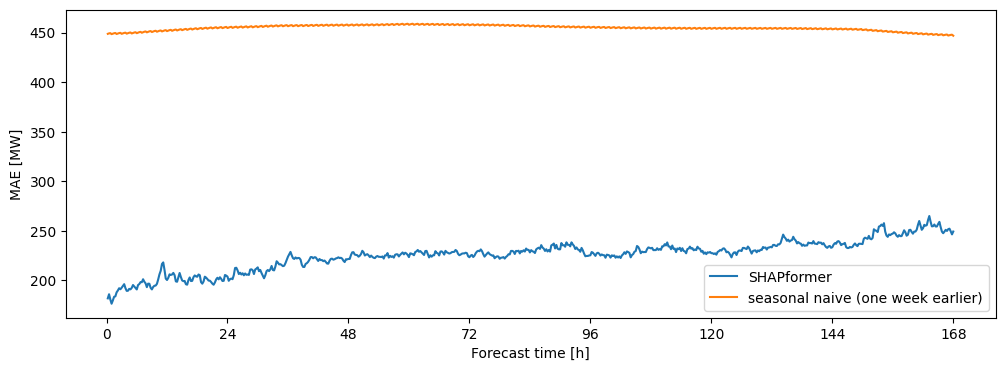

In [6]:
hours = np.arange(1, HORIZON + 1) / STEPS_PER_HOUR
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hours, np.abs(predictions - actuals).mean(axis=0), label="SHAPformer")
ax.plot(hours, np.abs(naive - actuals).mean(axis=0), label="seasonal naive (one week earlier)")
ax.set_xticks(range(0, HORIZON // STEPS_PER_HOUR + 1, 24))
ax.set_xlabel("Forecast time [h]")
ax.set_ylabel("MAE [MW]")
ax.legend()
plt.show()

## Forecast one week

`model.predict(past, future)` takes the last `INPUT_LENGTH` time steps before the forecast (with the target and all covariates) as `past`, and the `HORIZON` time steps to forecast (with the covariates only) as `future`. Here, we forecast the week starting on Monday, 15 April 2019, and compare the forecast with the actual load.

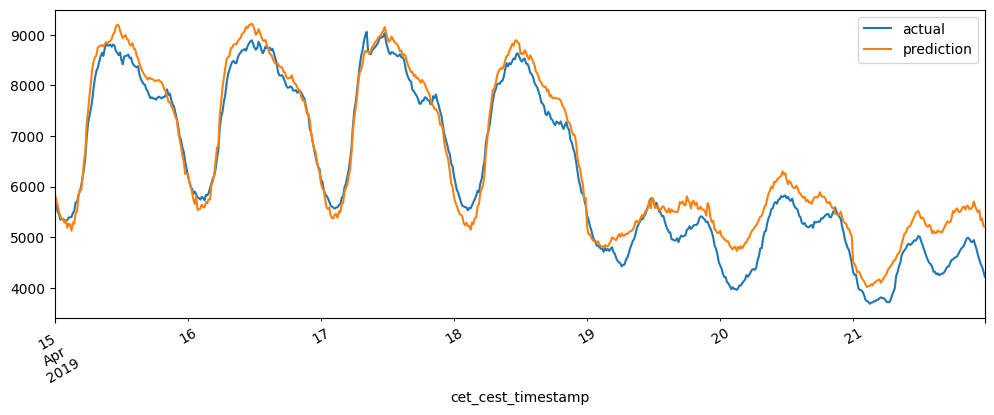

In [7]:
FORECAST_START = "2019-04-15 00:00:00+02:00"

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="load")

prediction = model.predict(past, future)

actual = df["load"].iloc[start:start + HORIZON]
comparison = pd.DataFrame({"actual": actual.to_numpy(), "prediction": prediction.to_numpy()},
                          index=pd.to_datetime(actual.index, utc=True).tz_convert("Europe/Berlin"))
comparison.plot(figsize=(12, 4), rot=30)
plt.show()

## Explain the forecast

`model.explain(past, future)` splits the forecast into contributions of the feature groups: one group per covariate and one group per day of the past load (`period 1` is the oldest day, `period 7` the most recent one). As before, `base` + the sum of all `shap_values` = `prediction`. The explanation also contains `periods`: the name, length and first and last time step of each period of the past load.

This forecast is explained with the exact method (`method="exact"`), which evaluates the model with all feature group subsets.

In [8]:
explanation = model.explain(past, future, method="exact")
print("max. |base + sum of SHAP values - prediction|:",
      (explanation["base"] + explanation["shap_values"].sum(axis=1) - explanation["prediction"]).abs().max())
explanation["periods"]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:10<00:00,  6.31it/s]


max. |base + sum of SHAP values - prediction|: 2.7284841053187847e-12


,length,start,end
name,,,
period 1,96,2019-04-08 00:00:00+02:00,2019-04-08 23:45:00+02:00
period 2,96,2019-04-09 00:00:00+02:00,2019-04-09 23:45:00+02:00
period 3,96,2019-04-10 00:00:00+02:00,2019-04-10 23:45:00+02:00
period 4,96,2019-04-11 00:00:00+02:00,2019-04-11 23:45:00+02:00
period 5,96,2019-04-12 00:00:00+02:00,2019-04-12 23:45:00+02:00
period 6,96,2019-04-13 00:00:00+02:00,2019-04-13 23:45:00+02:00
period 7,96,2019-04-14 00:00:00+02:00,2019-04-14 23:45:00+02:00


The explanation as a stacked area chart around the base value (dotted). With `mode="load"`, the periods are summed into one group; with `mode="periods"`, the covariates are summed into one group, so the contributions of the single periods become visible.

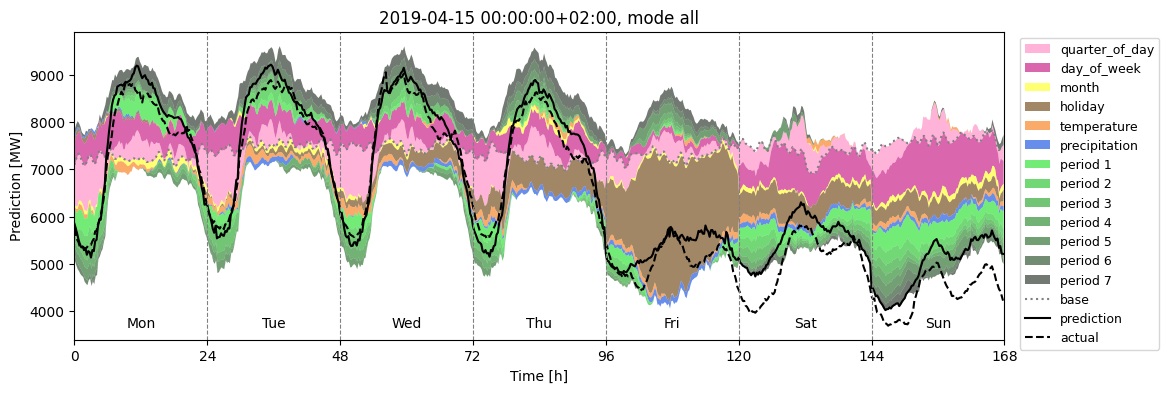

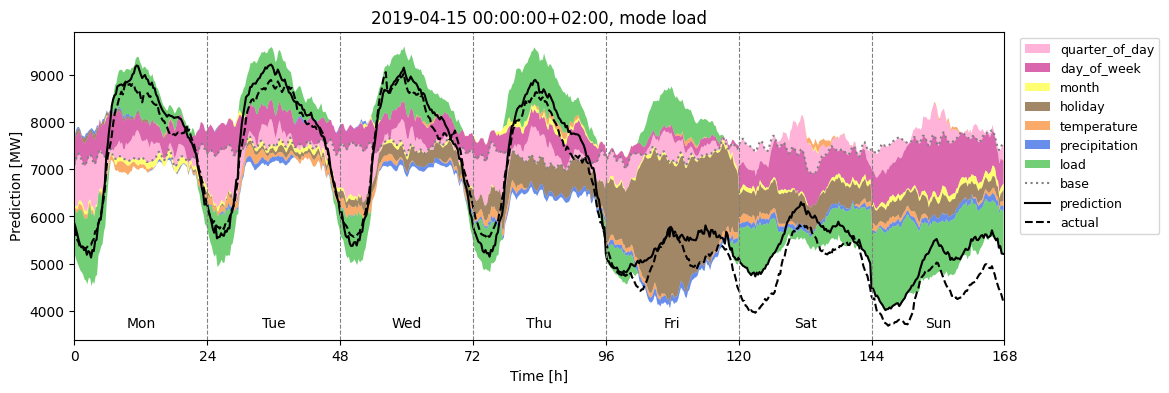

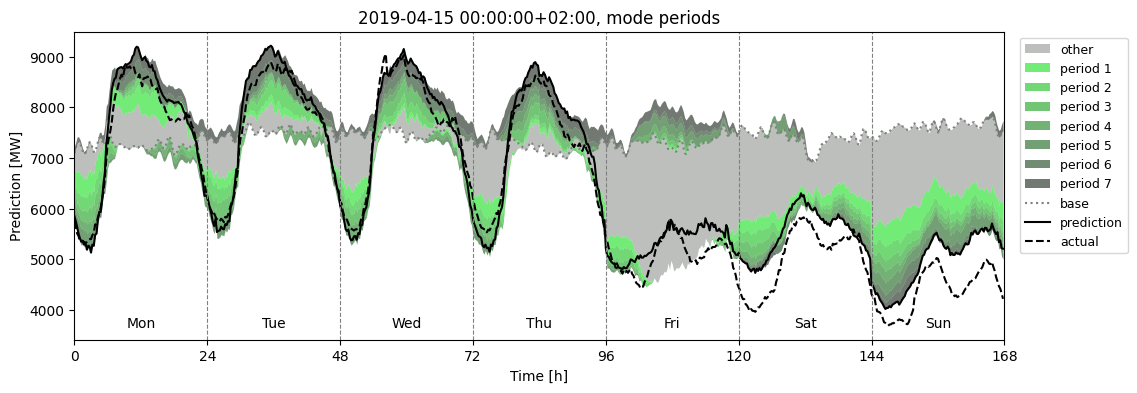

In [9]:
from shapformer import plot_explanation

for mode in ("all", "load", "periods"):
    plot_explanation(explanation, mode=mode, actual=actual, title=f"{FORECAST_START}, mode {mode}")
    plt.show()

## Dependence plots of many explanations

As in `training_dataframe.ipynb`: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted time step `DEPENDENCE_HORIZON` (here 24 hours after the forecast start) on the y-axis. For the load, the x-axis is the load one week before that time step, and the y-axis the sum of the contributions of all periods.

We explain 1000 random forecast starts in the validation period with the permutation method (`method="permutation"`, 10 permutations each).

1000it [06:26,  2.58it/s]


0.387 s per explanation on average


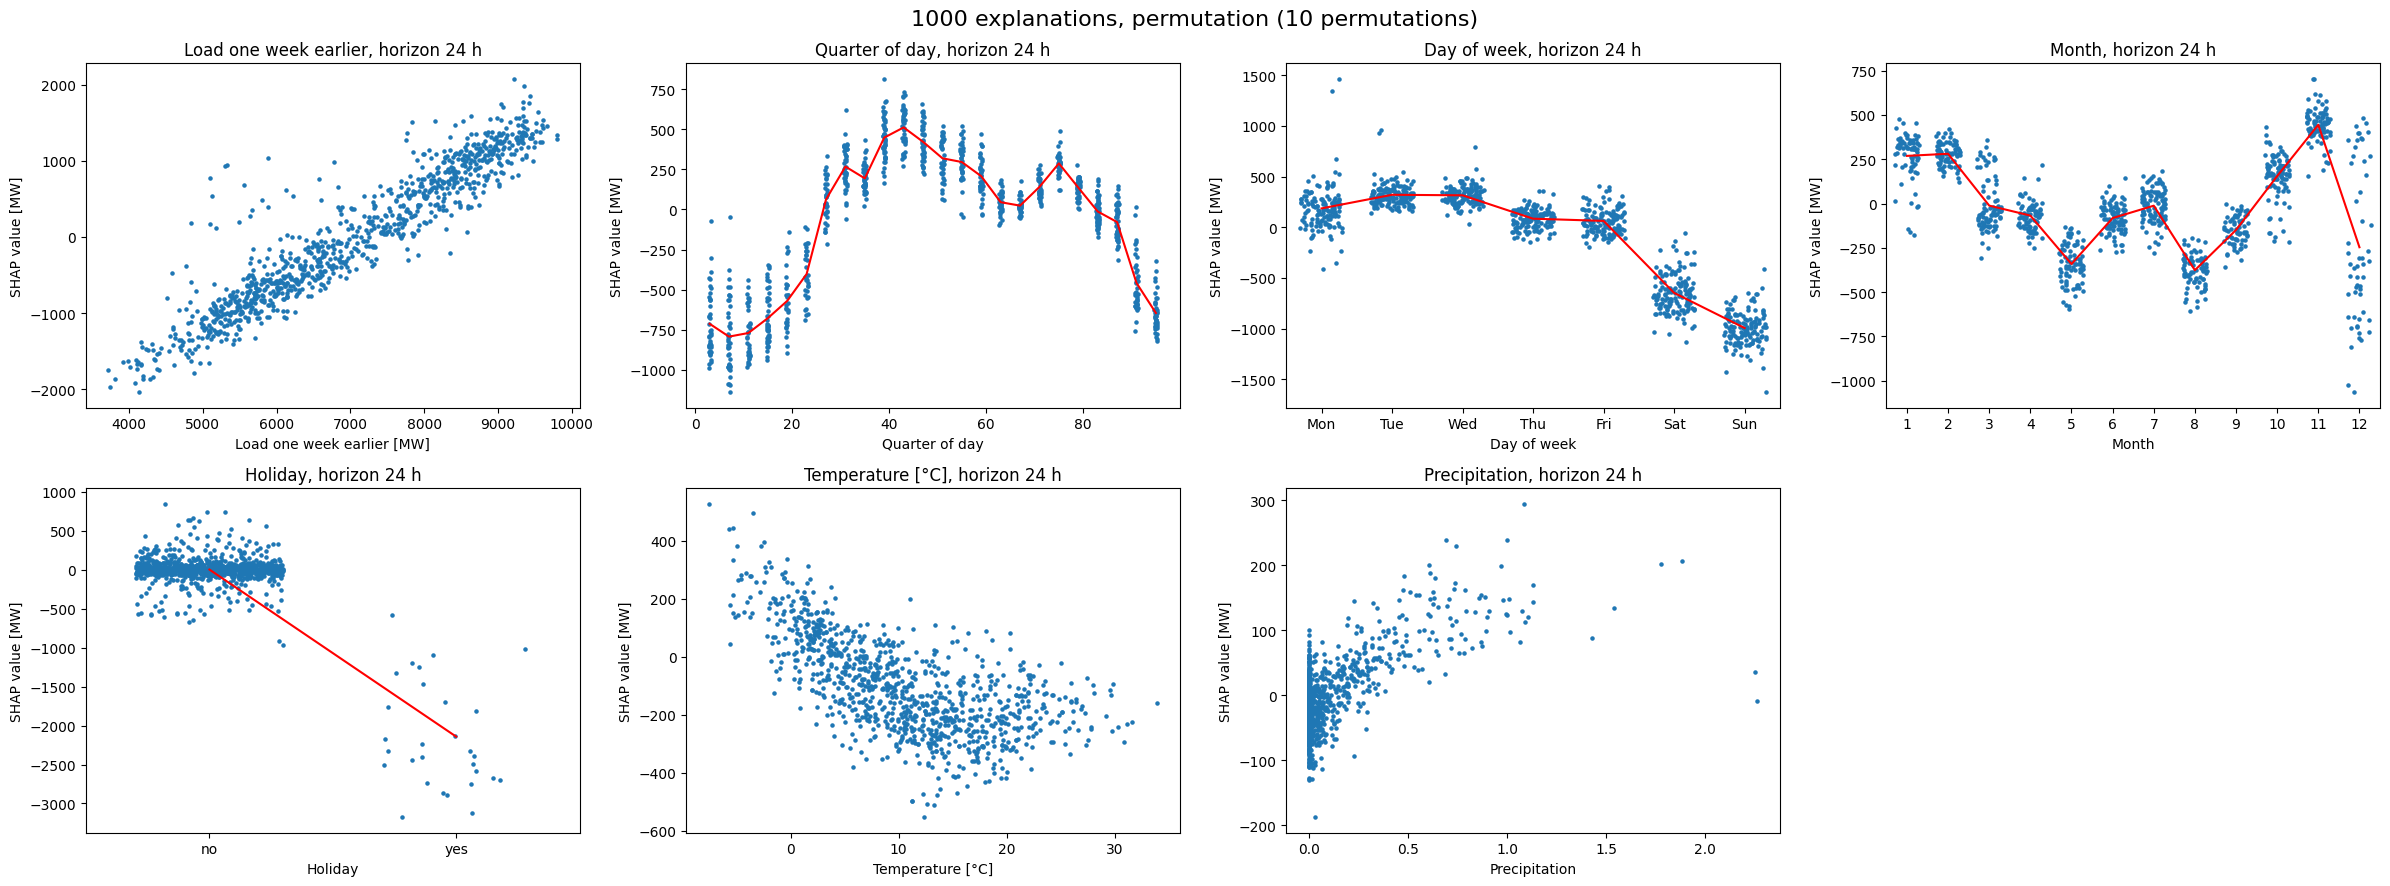

In [10]:
import math
import random
import time
from shapformer import plot_dependence

SEED = 42
N_PERMUTATIONS = 10  # permutations per explanation
DEPENDENCE_HORIZON = 96  # plot the SHAP values of this forecasted time step (24 hours after the start)
N_COLUMNS = 4

starts_1000 = random.Random(SEED).sample(evaluation_starts, 1000)

start_time = time.perf_counter()
explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], future_covariates.iloc[s:s + HORIZON], method="permutation",
                  n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in tqdm(enumerate(starts_1000))
]
print(f"{(time.perf_counter() - start_time) / len(explanations):.3f} s per explanation on average")

n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"1000 explanations, permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()

The mean absolute contribution of each feature group over the 1000 explanations and all forecasted time steps shows how much the model relies on each covariate and on each period of the past load.

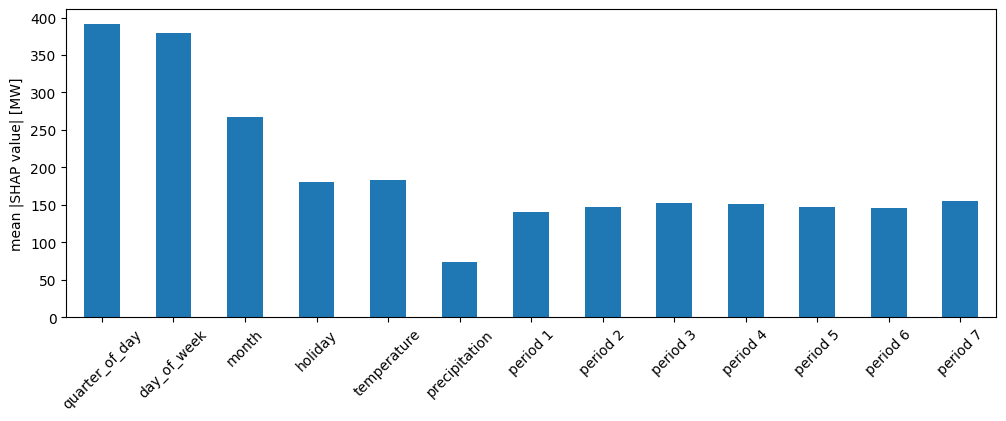

In [11]:
mean_abs = pd.concat([e["shap_values"].abs().mean() for e in explanations], axis=1).mean(axis=1)
ax = mean_abs.plot.bar(figsize=(12, 4), rot=45)
ax.set_ylabel("mean |SHAP value| [MW]")
plt.show()